# Maze9 Latent Clustering and Rollout MSE

This notebook visualizes two trained autoencoder checkpoints:

- latent clusters from final trajectory embeddings, plotted on the Maze9 `(x, y)` plane
- rollout pixel MSE per step for VAE and GRWM dynamics

Run `bash run_maze9_vae_grwm.sh` first, or update the paths below to point to existing checkpoints and metric summaries.

In [ ]:
from pathlib import Path
import json
import os
import sys

import h5py
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from sklearn.cluster import KMeans

ROOT = Path.cwd()
if not (ROOT / "run_maze9_vae_grwm.sh").exists():
    ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

from generate_latent_videos import load_autoencoder_model

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"ROOT={ROOT}")
print(f"device={device}")

## Paths

The defaults match `run_maze9_vae_grwm.sh`. Latent clustering uses `CLUSTER_DIR`, which defaults to `TRAIN_DIR`. Override with environment variables or edit the cell.

In [ ]:
TRAIN_DIR = Path(os.environ.get("TRAIN_DIR", "/path/to/9x9_n0.8"))
VAL_DIR = Path(os.environ.get("VAL_DIR", "/path/to/9x9_val"))
CLUSTER_DIR = Path(os.environ.get("CLUSTER_DIR", str(TRAIN_DIR)))

VAE_CKPT = Path(os.environ.get(
    "VAE_CKPT",
    ROOT / "checkpoints/vae32/last.ckpt",
))
GRWM_CKPT = Path(os.environ.get(
    "GRWM_CKPT",
    ROOT / "checkpoints/mcgr32/last.ckpt",
))

METRICS_DIR = Path(os.environ.get("METRICS_DIR", ROOT / "outputs/maze9_metrics"))

N_TRAJECTORIES = int(os.environ.get("N_TRAJECTORIES", 10_000))
N_CLUSTERS = int(os.environ.get("N_CLUSTERS", 20))
MAX_LENGTH = int(os.environ.get("MAX_LENGTH", 64))
IMAGE_SIZE = int(os.environ.get("IMAGE_SIZE", 32))
MAZE_SCALE = float(os.environ.get("MAZE_SCALE", 4.5))
POSE_CENTER = float(os.environ.get("POSE_CENTER", 1.0))
SEED = int(os.environ.get("SEED", 0))

print("TRAIN_DIR", TRAIN_DIR)
print("VAL_DIR", VAL_DIR)
print("CLUSTER_DIR", CLUSTER_DIR)
print("VAE_CKPT", VAE_CKPT)
print("GRWM_CKPT", GRWM_CKPT)
print("METRICS_DIR", METRICS_DIR)

In [12]:
for path in [CLUSTER_DIR, VAE_CKPT, GRWM_CKPT, METRICS_DIR]:
    if not Path(path).exists():
        raise FileNotFoundError(path)

## Latent Embeddings

For each trajectory in the training set, this notebook encodes the final available window and keeps the last latent. The latent is clustered with KMeans, then colored on the raw Maze9 `(x, y)` plane.

In [13]:
def load_trajectory_window(maze_dir: Path, traj_idx: int, start_idx: int, end_idx: int, size: int):
    images = np.load(maze_dir / "obs" / f"{traj_idx}.npy", mmap_mode="r")[start_idx:end_idx]
    images = images.astype(np.float32) / 127.5 - 1.0
    if images.shape[-2:] != (size, size):
        images_t = torch.from_numpy(np.ascontiguousarray(images))
        images = F.interpolate(images_t, size=(size, size), mode="bilinear", align_corners=False).numpy()
    return torch.tensor(images, dtype=torch.float32)


def collect_final_latents(model, maze_dir: Path, limit: int, max_length: int, size: int):
    info_path = maze_dir / "info.hdf5"
    latents = []
    xy = []
    traj_ids = []
    with h5py.File(info_path, "r") as h5:
        trajectory_indices = h5["trajectory_indices"][:]
        steps = h5["steps"]
        total = len(trajectory_indices) - 1
        for traj_idx in range(total):
            obs_path = maze_dir / "obs" / f"{traj_idx}.npy"
            if not obs_path.exists():
                continue
            global_start = int(trajectory_indices[traj_idx])
            global_end = int(trajectory_indices[traj_idx + 1])
            length = global_end - global_start
            if length <= 0:
                continue
            local_start = max(0, length - max_length)
            local_end = length
            images = load_trajectory_window(maze_dir, traj_idx, local_start, local_end, size)
            batch = {
                "image": images.unsqueeze(0).to(device),
                "padding_mask": torch.ones(1, images.shape[0], dtype=torch.bool, device=device),
            }
            with torch.inference_mode():
                z = model.get_val_latents(batch)[0, -1].detach().float().cpu().reshape(-1).numpy()
            last_step = np.asarray(steps[global_end - 1], dtype=np.float32)
            latents.append(z)
            xy.append(last_step[:2])
            traj_ids.append(traj_idx)
            if len(latents) >= limit:
                break
    return np.stack(latents), np.stack(xy), np.asarray(traj_ids)


def cluster_latents(latents, n_clusters: int, seed: int):
    n_clusters = min(n_clusters, len(latents))
    model = KMeans(n_clusters=n_clusters, random_state=seed, n_init=10)
    return model.fit_predict(latents)

In [ ]:
vae_model = load_autoencoder_model(str(VAE_CKPT), "grvae", device)
grwm_model = load_autoencoder_model(str(GRWM_CKPT), "grvae", device)

vae_latents, vae_xy, vae_traj_ids = collect_final_latents(
    vae_model, CLUSTER_DIR, N_TRAJECTORIES, MAX_LENGTH, IMAGE_SIZE
)
grwm_latents, grwm_xy, grwm_traj_ids = collect_final_latents(
    grwm_model, CLUSTER_DIR, N_TRAJECTORIES, MAX_LENGTH, IMAGE_SIZE
)

vae_labels = cluster_latents(vae_latents, N_CLUSTERS, SEED)
grwm_labels = cluster_latents(grwm_latents, N_CLUSTERS, SEED)

print("VAE", vae_latents.shape, vae_xy.shape)
print("GRWM", grwm_latents.shape, grwm_xy.shape)

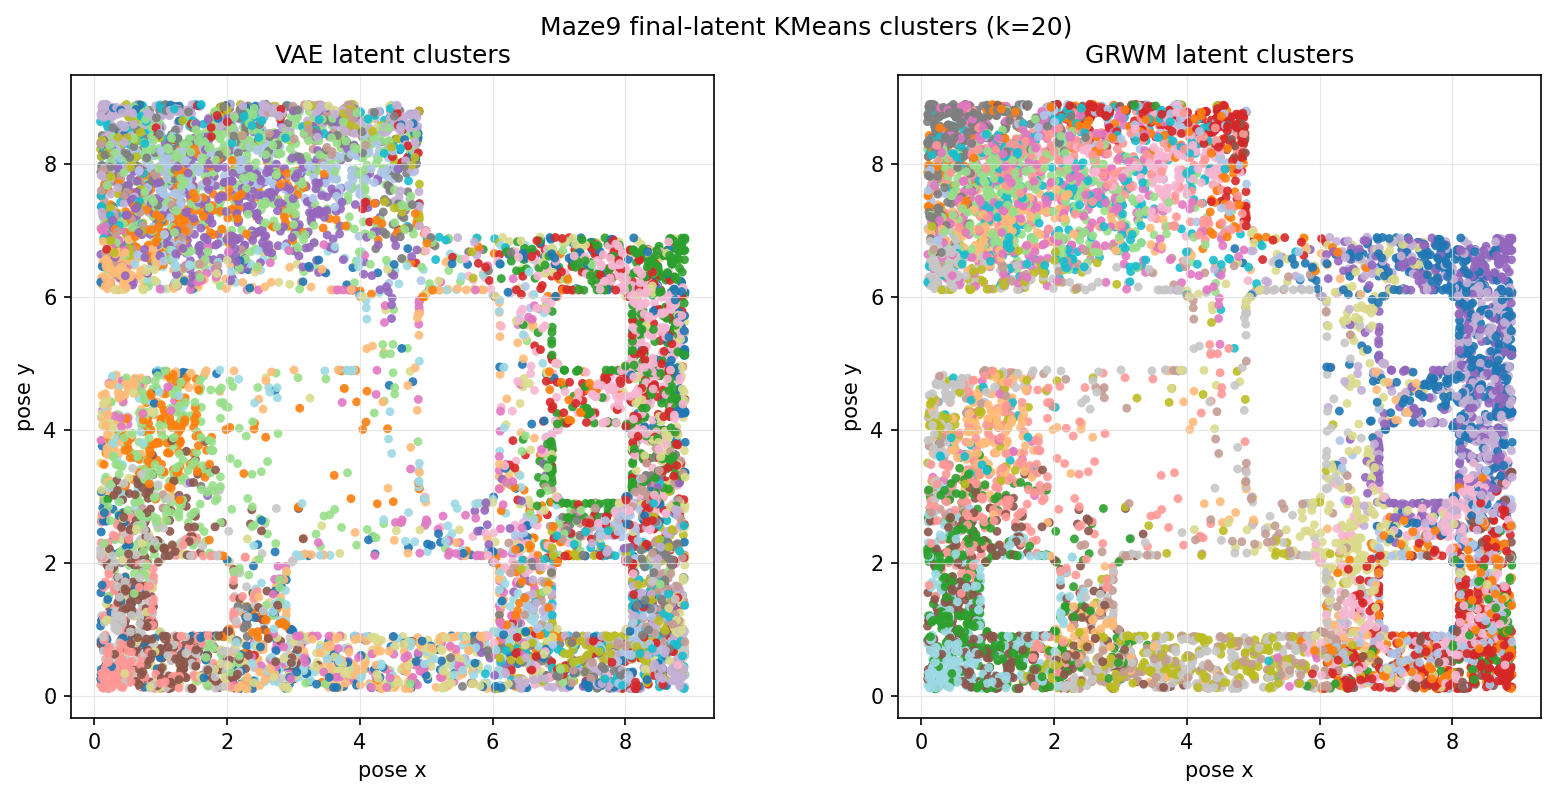

In [ ]:
def plot_latent_clusters(ax, xy, labels, title):
    scatter = ax.scatter(
        xy[:, 0],
        xy[:, 1],
        c=labels,
        cmap="tab20",
        s=18,
        linewidths=0,
        alpha=0.9,
    )
    ax.set_title(title)
    ax.set_xlabel("pose x")
    ax.set_ylabel("pose y")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(True, color="#311717", linewidth=0.6, alpha=0.7)
    return scatter


fig, axes = plt.subplots(1, 2, figsize=(11, 5), dpi=150, constrained_layout=True)
plot_latent_clusters(axes[0], vae_xy, vae_labels, "VAE latent clusters")
plot_latent_clusters(axes[1], grwm_xy, grwm_labels, "GRWM latent clusters")
fig.suptitle(f"Maze9 final-latent KMeans clusters (k={N_CLUSTERS})", y=1.03)
plt.show()

## Rollout MSE

The training script writes one summary JSON per model. The helper below finds the default VAE and GRWM summaries, then plots normalized MSE per rollout step.

In [ ]:
def find_summary(metrics_dir: Path, patterns):
    for pattern in patterns:
        matches = sorted(metrics_dir.glob(pattern))
        if matches:
            return matches[-1]
    raise FileNotFoundError(f"No summary matched: {patterns}")


vae_summary_env = os.environ.get("VAE_MSE_SUMMARY")
grwm_summary_env = os.environ.get("GRWM_MSE_SUMMARY")

VAE_MSE_SUMMARY = Path(vae_summary_env) if vae_summary_env else find_summary(METRICS_DIR, [
    "maze9_vae32*_rollout_pixel_mse_summary.json",
    "*vae*rollout_pixel_mse_summary.json",
])
GRWM_MSE_SUMMARY = Path(grwm_summary_env) if grwm_summary_env else find_summary(METRICS_DIR, [
    "maze9_grwm32*_rollout_pixel_mse_summary.json",
    "*grwm*rollout_pixel_mse_summary.json",
])

print("VAE_MSE_SUMMARY", VAE_MSE_SUMMARY)
print("GRWM_MSE_SUMMARY", GRWM_MSE_SUMMARY)

In [16]:
def load_mse_series(path: Path):
    data = json.loads(path.read_text(encoding="utf-8"))
    pre_k = int(data.get("pre_k", 0) or 0)
    values = data["mse_norm_per_step_mean"]
    points = [(idx - pre_k + 1, value) for idx, value in enumerate(values) if value is not None]
    x = np.asarray([step for step, _ in points], dtype=np.int64)
    y = np.asarray([value for _, value in points], dtype=np.float32)
    return data, x, y


vae_mse, vae_steps, vae_values = load_mse_series(VAE_MSE_SUMMARY)
grwm_mse, grwm_steps, grwm_values = load_mse_series(GRWM_MSE_SUMMARY)

print("VAE global normalized MSE:", vae_mse["mse_norm_global_mean"])
print("GRWM global normalized MSE:", grwm_mse["mse_norm_global_mean"])
print("VAE global 255-scale MSE:", vae_mse["mse_255_global_mean"])
print("GRWM global 255-scale MSE:", grwm_mse["mse_255_global_mean"])

VAE global normalized MSE: 0.11488793045282364
GRWM global normalized MSE: 0.07000662386417389
VAE global 255-scale MSE: 1867.6468505859375
GRWM global 255-scale MSE: 1138.0450439453125


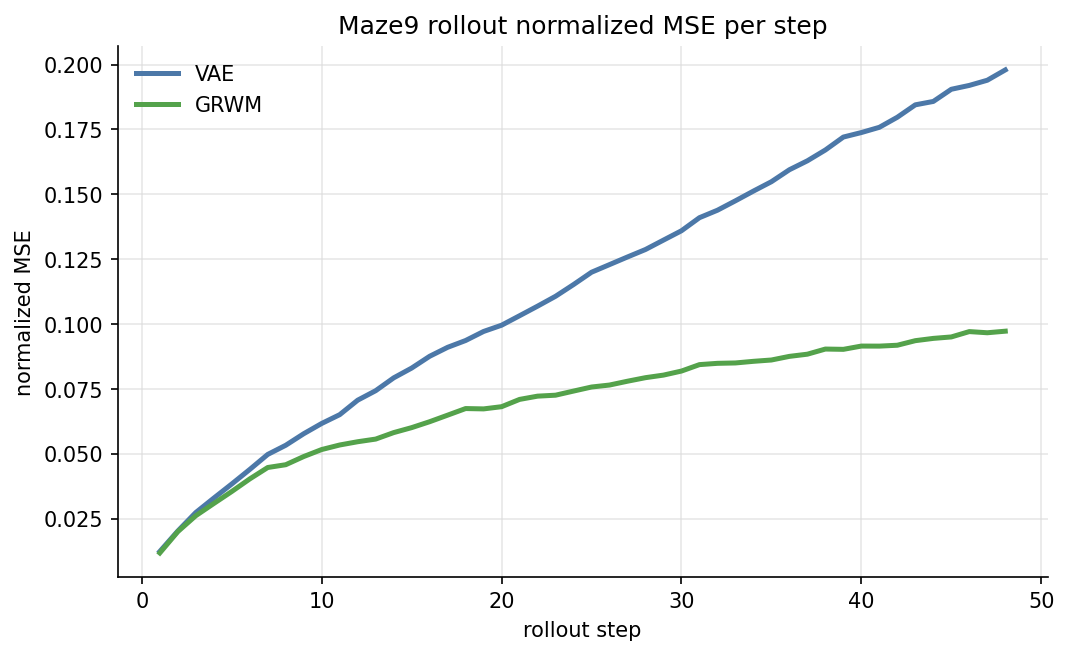

In [17]:
fig, ax = plt.subplots(figsize=(8, 4.6), dpi=150)
ax.plot(vae_steps, vae_values, label="VAE", linewidth=2.4, color="#4C78A8")
ax.plot(grwm_steps, grwm_values, label="GRWM", linewidth=2.4, color="#54A24B")
ax.set_title("Maze9 rollout normalized MSE per step")
ax.set_xlabel("rollout step")
ax.set_ylabel("normalized MSE")
ax.grid(True, color="#dddddd", linewidth=0.8, alpha=0.7)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False)
plt.show()